# **Olist E-Commerce Data Analytics**

## **1. Environment Setup & Data Loading**

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


### **Load Olist Dataset**

In [61]:
# Load Olist Dataset

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

data_path = PROJECT_ROOT / "data" / "raw"

if not data_path.is_dir():
    raise FileNotFoundError("Dataset directory not found")

customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
geolocation = pd.read_csv(data_path / "olist_geolocation_dataset.csv")
order_items = pd.read_csv(data_path / "olist_order_items_dataset.csv")
payments = pd.read_csv(data_path / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(data_path / "olist_order_reviews_dataset.csv")
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
products = pd.read_csv(data_path / "olist_products_dataset.csv")
sellers = pd.read_csv(data_path / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(
    data_path / "product_category_name_translation.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


## **2. Data Understanding**

### **Dataset Overview**

In [62]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

overview = []

for name, df in datasets.items():
    overview.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    })

overview_df = pd.DataFrame(overview)
overview_df

,Dataset,Rows,Columns
0,Customers,99441,5
1,Geolocation,1000163,5
2,Order Items,112650,7
3,Payments,103886,5
4,Reviews,99224,7
5,Orders,99441,8
6,Products,32951,9
7,Sellers,3095,4
8,Category Translation,71,2


### **Columns and Data Types**

In [63]:
# Check columns and data types of each dataset
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.dtypes)


Customers
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Geolocation
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Order Items
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

Payments
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

Reviews
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment

### **Missing Values**

In [64]:
# Check missing values in each dataset
for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{name}")
    print(missing if not missing.empty else "No missing values")


Customers
No missing values

Geolocation
No missing values

Order Items
No missing values

Payments
No missing values

Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Sellers
No missing values

Category Translation
No missing values


- Phần lớn các bảng có chất lượng dữ liệu khá tốt và không xuất hiện giá trị thiếu.
- Bảng Reviews có lượng dữ liệu thiếu lớn ở `review_comment_title` và `review_comment_message`. Điều này hợp lý vì khách hàng có thể chấm điểm mà không cần để lại tiêu đề hoặc nội dung nhận xét.
- Bảng Orders có một số giá trị thiếu ở các mốc thời gian phê duyệt và giao hàng. Các giá trị này có thể liên quan đến những đơn hàng chưa hoàn tất, bị hủy hoặc không được giao thành công.
- Không nên xóa toàn bộ các dòng có giá trị thiếu ngay lập tức. Việc xử lý sẽ phụ thuộc vào mục đích của từng phân tích.

### **Duplicate Records**

In [65]:
# Check duplicate rows in each dataset
for name, df in datasets.items():
    duplicates = df.duplicated().sum()
    print(f"{name}: {duplicates}")

Customers: 0
Geolocation: 261831
Order Items: 0
Payments: 0
Reviews: 0
Orders: 0
Products: 0
Sellers: 0
Category Translation: 0


- 8/9 bảng không xuất hiện bản ghi trùng lặp hoàn toàn.
- Riêng bảng Geolocation có 261,831 bản ghi trùng lặp hoàn toàn.
- Kiểm tra kỹ đặc điểm của bảng Geolocation trước khi quyết định loại bỏ duplicate, tránh làm thay đổi thông tin vị trí cần thiết cho các phân tích sau.

### **Geolocation Duplicate Analysis**

In [66]:
# Compare geolocation data before and after removing duplicates
geo_original_rows = len(geolocation)
geo_unique_rows = len(geolocation.drop_duplicates())
geo_duplicate_rows = geolocation.duplicated().sum()

print(f"Original rows: {geo_original_rows}")
print(f"Duplicate rows: {geo_duplicate_rows}")
print(f"Unique rows: {geo_unique_rows}")
print(f"Duplicate rate: {geo_duplicate_rows / geo_original_rows * 100:.2f}%")

Original rows: 1000163
Duplicate rows: 261831
Unique rows: 738332
Duplicate rate: 26.18%


- Bảng Geolocation có 1,000,163 bản ghi, trong đó 261,831 bản ghi (26.18%) bị trùng lặp hoàn toàn.
- Các bản ghi trùng lặp không cung cấp thêm thông tin vị trí và có thể làm sai lệch kết quả khi thực hiện các phép tổng hợp.

=> Do đó, các bản ghi trùng lặp hoàn toàn trong bảng Geolocation sẽ được loại bỏ trong bước Data Cleaning.

## **3. Data Cleaning & Preprocessing**

### **Remove Duplicate Records**

In [67]:
# Remove duplicate rows from geolocation
geolocation = geolocation.drop_duplicates().reset_index(drop=True)

# Update dataset dictionary
datasets["Geolocation"] = geolocation

print(f"Geolocation rows after cleaning: {len(geolocation)}")

Geolocation rows after cleaning: 738332


### **Convert Date Columns**

In [68]:
# Convert order date columns to datetime
order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in order_date_columns:
    orders[col] = pd.to_datetime(orders[col])

# Convert other date columns to datetime
order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"])

reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])


In [69]:
# Check converted date columns
print(orders[order_date_columns].dtypes)
print(order_items[["shipping_limit_date"]].dtypes)
print(reviews[["review_creation_date", "review_answer_timestamp"]].dtypes)

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object
shipping_limit_date    datetime64[us]
dtype: object
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


### **Feature Engineering**

In [70]:
# Create delivery-related features
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

orders["is_late"] = (orders["delivery_delay_days"] > 0).astype(int)

In [71]:
# Check created delivery features
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_days",
        "delivery_delay_days",
        "is_late"
    ]
].head()

,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_delay_days,is_late
0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488,0
1,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729,0
2,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498,0
3,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069,0
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171,0


### **Delivery Feature Summary**

In [72]:
# Summarize delivery performance
delivery_summary = orders[
    ["delivery_days", "delivery_delay_days"]
].describe()

delivery_summary

,delivery_days,delivery_delay_days
count,96476.000000,96476.000000
mean,12.558702,-11.179120
std,9.546530,10.186113
min,0.533414,-146.016123
25%,6.766403,-16.244384
50%,10.217755,-11.948941
75%,15.720327,-6.390000
max,209.628611,188.975081


In [73]:
# Calculate late delivery rate
delivered_orders = orders["delivery_delay_days"].notna().sum()
late_orders = (orders["delivery_delay_days"] > 0).sum()
late_rate = late_orders / delivered_orders * 100

print(f"Delivered orders: {delivered_orders}")
print(f"Late orders: {late_orders}")
print(f"Late delivery rate: {late_rate:.2f}%")

Delivered orders: 96476
Late orders: 7827
Late delivery rate: 8.11%


- Trong 96,476 đơn hàng có đầy đủ thông tin giao hàng, thời gian giao hàng trung bình là khoảng 12.56 ngày và trung vị là 10.22 ngày.
- Phần lớn đơn hàng được giao sớm hơn thời gian dự kiến, trung bình khoảng 11.18 ngày.
- Chỉ 8.11% đơn hàng được giao trễ so với thời gian dự kiến, cho thấy hiệu suất giao hàng nhìn chung khá tốt.
- Tuy nhiên, dữ liệu vẫn tồn tại một số trường hợp bất thường với thời gian giao hàng và mức độ trễ rất cao. Đây có thể là nhóm đơn hàng cần được phân tích sâu hơn về ảnh hưởng đến trải nghiệm khách hàng.

In [74]:
# Correct late delivery status for orders without delivery data
orders["is_late"] = np.where(
    orders["delivery_delay_days"].isna(),
    np.nan,
    (orders["delivery_delay_days"] > 0).astype(int)
)

print(orders["is_late"].value_counts(dropna=False))

is_late
0.0    88649
1.0     7827
NaN     2965
Name: count, dtype: int64


## **4. Exploratory Data Analysis (EDA)**

### **Delivery Performance and Customer Satisfaction**

In [75]:
# Merge orders with customer reviews
delivery_reviews = orders[
    ["order_id", "delivery_days", "delivery_delay_days", "is_late"]
].merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

delivery_reviews.head()

,order_id,delivery_days,delivery_delay_days,is_late,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,0.0,4
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,0.0,4
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,0.0,5
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,0.0,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,0.0,5


In [76]:
# Check merged dataset
print(f"Rows: {len(delivery_reviews)}")
print(delivery_reviews.isnull().sum())

Rows: 99224
order_id                  0
delivery_days          2865
delivery_delay_days    2865
is_late                2865
review_score              0
dtype: int64


### **Impact of Late Delivery on Review Score**

In [77]:
# Compare review scores by delivery status
review_by_delivery = (
    delivery_reviews
    .dropna(subset=["is_late"])
    .groupby("is_late")["review_score"]
    .agg(["count", "mean", "median"])
    .round(2)
)

review_by_delivery.index = ["On-time / Early", "Late"]

review_by_delivery

,count,mean,median
On-time / Early,88658,4.29,5.0
Late,7701,2.57,2.0


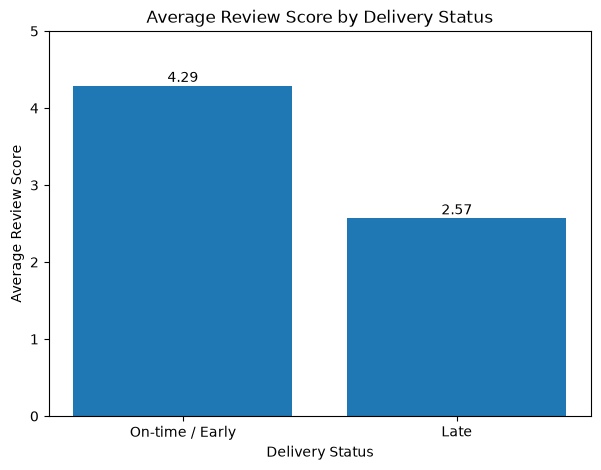

In [78]:
# Visualize average review score by delivery status
avg_review = review_by_delivery["mean"]

plt.figure(figsize=(7, 5))
bars = plt.bar(avg_review.index, avg_review.values)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

for bar, value in zip(bars, avg_review.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.05,
        f"{value:.2f}",
        ha="center"
    )

plt.show()

- Các đơn hàng được giao đúng hạn hoặc sớm có điểm đánh giá trung bình 4.29/5, trong khi các đơn giao trễ chỉ đạt 2.57/5.
- Điểm đánh giá trung bình của nhóm giao trễ thấp hơn 1.72 điểm, cho thấy mối liên hệ rõ rệt giữa hiệu suất giao hàng và mức độ hài lòng của khách hàng.
- Kết quả cho thấy việc hạn chế giao hàng trễ có thể là một yếu tố quan trọng để cải thiện trải nghiệm và mức độ hài lòng của khách hàng.

### **Statistical Test: Delivery Status vs Review Score**

In [79]:
from scipy.stats import mannwhitneyu

print("SciPy imported successfully!")

SciPy imported successfully!


In [80]:
# Prepare review scores for both delivery groups
on_time_reviews = delivery_reviews.loc[
    delivery_reviews["is_late"] == 0, "review_score"
]

late_reviews = delivery_reviews.loc[
    delivery_reviews["is_late"] == 1, "review_score"
]

# Perform Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    on_time_reviews,
    late_reviews,
    alternative="two-sided"
)

print(f"U statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.6f}")

U statistic: 530299366.50
P-value: 0.000000


In [81]:
# Calculate rank-biserial effect size
n1 = len(on_time_reviews)
n2 = len(late_reviews)

effect_size = (2 * u_stat) / (n1 * n2) - 1

print(f"Effect size: {effect_size:.3f}")

Effect size: 0.553


- Các đơn hàng giao đúng hạn hoặc sớm có điểm đánh giá trung bình 4.29/5, cao hơn đáng kể so với 2.57/5 ở nhóm giao trễ.
- Kiểm định Mann–Whitney U cho kết quả p-value < 0.05, cho thấy sự khác biệt về điểm đánh giá giữa hai nhóm có ý nghĩa thống kê.
- Effect size đạt 0.553, cho thấy mức độ khác biệt giữa hai nhóm là đáng kể, không chỉ đơn thuần xuất hiện do kích thước mẫu lớn.
- Kết quả cung cấp bằng chứng mạnh về mối liên hệ giữa hiệu suất giao hàng và sự hài lòng của khách hàng. Việc giảm tỷ lệ giao hàng trễ có thể là một hướng quan trọng để cải thiện trải nghiệm khách hàng.

## **5. Customer Segmentation**

### **RFM Analysis**

In [82]:
# Prepare customer order data
customer_orders = orders[
    ["order_id", "customer_id", "order_status", "order_purchase_timestamp"]
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6


In [83]:
# Check customer order data
print(f"Rows: {len(customer_orders)}")
print(f"Unique customers: {customer_orders['customer_unique_id'].nunique()}")
print(customer_orders["order_status"].value_counts())

Rows: 99441


Unique customers: 96096
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [84]:
# Keep only completed orders for RFM analysis
rfm_orders = customer_orders[
    customer_orders["order_status"] == "delivered"
].copy()

print(f"Delivered orders: {len(rfm_orders)}")
print(f"Unique customers: {rfm_orders['customer_unique_id'].nunique()}")

Delivered orders: 96478
Unique customers: 93358


In [85]:
# Calculate total payment value for each order
order_payments = (
    payments
    .groupby("order_id", as_index=False)["payment_value"]
    .sum()
)

order_payments.head()

,order_id,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [86]:
# Add payment value to completed orders
rfm_data = rfm_orders.merge(
    order_payments,
    on="order_id",
    how="left"
)

print(f"Rows: {len(rfm_data)}")
print(f"Missing payment values: {rfm_data['payment_value'].isnull().sum()}")

rfm_data.head()

Rows: 96478
Missing payment values: 1


,order_id,customer_id,order_status,order_purchase_timestamp,customer_unique_id,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6,28.62


In [87]:
# Remove order without payment information
rfm_data = rfm_data.dropna(subset=["payment_value"]).copy()

print(f"Rows after cleaning: {len(rfm_data)}")

Rows after cleaning: 96477


In [88]:
# Set reference date for Recency calculation
reference_date = rfm_data["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

print(f"Last purchase date: {rfm_data['order_purchase_timestamp'].max()}")
print(f"Reference date: {reference_date}")

Last purchase date: 2018-08-29 15:00:37
Reference date: 2018-08-30 15:00:37


In [89]:
# Calculate RFM metrics for each customer
rfm = (
    rfm_data
    .groupby("customer_unique_id")
    .agg(
        Recency=(
            "order_purchase_timestamp",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("order_id", "nunique"),
        Monetary=("payment_value", "sum")
    )
    .reset_index()
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


In [90]:
# Summarize RFM metrics
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

,Recency,Frequency,Monetary
count,93357.00,93357.00,93357.00
mean,237.94,1.03,165.20
std,152.58,0.21,226.31
min,1.00,1.00,9.59
25%,114.00,1.00,63.06
50%,219.00,1.00,107.78
75%,346.00,1.00,182.56
max,695.00,15.00,13664.08


- Phần lớn khách hàng chỉ thực hiện một giao dịch hoàn tất trong toàn bộ khoảng thời gian quan sát, thể hiện qua trung vị và cả Q1–Q3 của Frequency đều bằng 1.
- Frequency trung bình chỉ đạt 1.03 đơn hàng/khách hàng, cho thấy tỷ lệ mua lại của khách hàng tương đối thấp.
- Monetary có sự phân hóa lớn: mức chi tiêu trung vị là 107.78, trong khi giá trị lớn nhất đạt 13,664.08. Điều này cho thấy tồn tại một nhóm nhỏ khách hàng có giá trị giao dịch rất cao.
- Sự khác biệt về Recency và Monetary có thể đóng vai trò quan trọng trong việc phân nhóm khách hàng, trong khi Frequency có độ biến thiên tương đối thấp.

### **Customer Purchase Frequency**

In [91]:
# Analyze customer purchase frequency
frequency_summary = rfm["Frequency"].value_counts().sort_index()

frequency_summary

Frequency
1     90556
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [92]:
# Calculate one-time and repeat customer rates
one_time_customers = (rfm["Frequency"] == 1).sum()
repeat_customers = (rfm["Frequency"] > 1).sum()
total_customers = len(rfm)

print(f"One-time customers: {one_time_customers} ({one_time_customers / total_customers * 100:.2f}%)")
print(f"Repeat customers: {repeat_customers} ({repeat_customers / total_customers * 100:.2f}%)")

One-time customers: 90556 (97.00%)
Repeat customers: 2801 (3.00%)


- Có tới 97% khách hàng chỉ thực hiện một đơn hàng hoàn tất, trong khi tỷ lệ khách hàng quay lại mua từ lần thứ hai trở lên chỉ đạt 3%.
- Điều này cho thấy hành vi mua lặp lại trên Olist trong khoảng thời gian quan sát tương đối thấp và phần lớn khách hàng chỉ phát sinh một giao dịch.
- Customer retention và khả năng thúc đẩy khách hàng quay lại mua hàng là một cơ hội đáng chú ý để cải thiện giá trị vòng đời khách hàng.

### **K-Means Customer Segmentation**

#### **Data Preprocessing**

In [93]:
# Import tools for clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [94]:
# Prepare RFM features for clustering
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Reduce skewness of RFM features
rfm_log = np.log1p(rfm_features)

rfm_log.describe().round(2)

,Recency,Frequency,Monetary
count,93357.00,93357.00,93357.00
mean,5.17,0.71,4.73
std,0.93,0.08,0.81
min,0.69,0.69,2.36
25%,4.74,0.69,4.16
50%,5.39,0.69,4.69
75%,5.85,0.69,5.21
max,6.55,2.77,9.52


In [95]:
# Standardize RFM features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)

rfm_scaled.describe().round(2)

,Recency,Frequency,Monetary
count,93357.00,93357.00,93357.00
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-4.79,-0.17,-2.93
25%,-0.45,-0.17,-0.70
50%,0.24,-0.17,-0.05
75%,0.73,-0.17,0.60
max,1.48,26.95,5.93


#### **Selecting the Optimal Number of Clusters**

In [96]:
# Evaluate different numbers of clusters
k_values = range(2, 7)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

cluster_evaluation = pd.DataFrame({
    "K": k_values,
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

cluster_evaluation.round(3)

,K,Inertia,Silhouette Score
0,2,190212.019,0.715
1,3,129160.669,0.420
2,4,82895.745,0.395
3,5,68319.638,0.357
4,6,58425.992,0.354


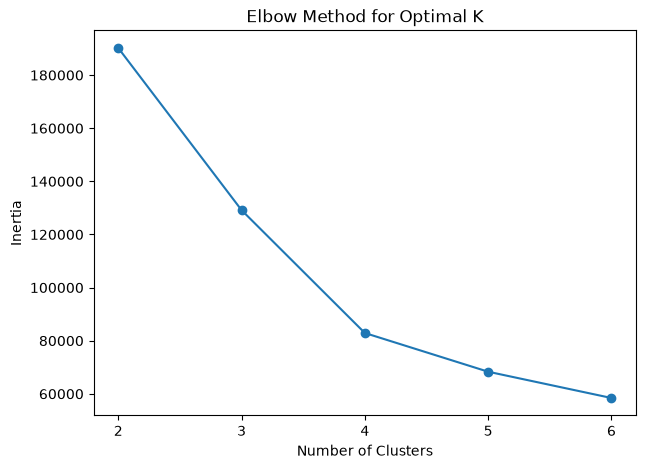

In [97]:
# Plot Elbow Method
plt.figure(figsize=(7, 5))

plt.plot(
    cluster_evaluation["K"],
    cluster_evaluation["Inertia"],
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(cluster_evaluation["K"])

plt.show()

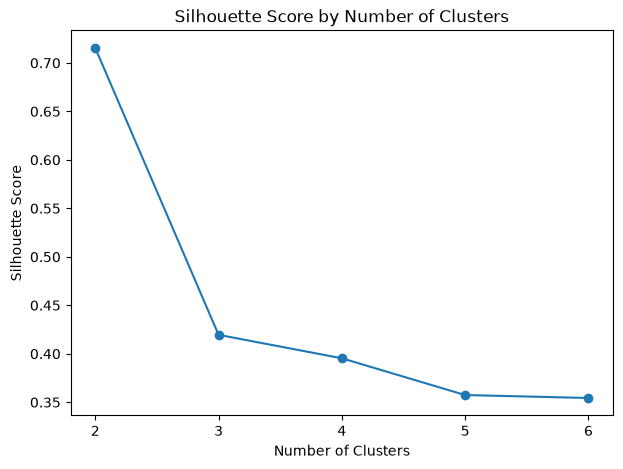

In [98]:
# Plot Silhouette Scores
plt.figure(figsize=(7, 5))

plt.plot(
    cluster_evaluation["K"],
    cluster_evaluation["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(cluster_evaluation["K"])

plt.show()

- Silhouette Score đạt cao nhất tại K=2 với 0.715, cho thấy cấu trúc hai cụm có mức độ phân tách rất rõ.
- Elbow Method cho thấy mức giảm Inertia bắt đầu chậm lại đáng kể từ khoảng K=4.
- Để cân bằng giữa chất lượng phân cụm và khả năng phân tích nhiều nhóm khách hàng có ý nghĩa kinh doanh, K=4 được lựa chọn cho mô hình K-Means.

#### **K-Means Model**

In [99]:
# Train K-Means model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm["Cluster"].value_counts().sort_index()

Cluster
0    32185
1    42287
2     2801
3    16084
Name: count, dtype: int64

In [100]:
# Profile customer clusters
cluster_profile = (
    rfm
    .groupby("Cluster")
    .agg(
        Customers=("customer_unique_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customers"] / len(rfm) * 100
).round(2)

cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
Cluster,,,,,
0,32185,272.48,1.00,295.78,34.48
1,42287,287.33,1.00,68.21,45.30
2,2801,220.29,2.11,308.59,3.00
3,16084,42.02,1.00,133.91,17.23


- K-Means phân chia khách hàng thành 4 nhóm có đặc điểm hành vi khác biệt rõ ràng.
- Nhóm Loyal High-Value chỉ chiếm 3.00% khách hàng nhưng có tần suất mua cao nhất (2.11 đơn) và mức chi tiêu trung bình cao nhất (308.59), cho thấy đây là nhóm khách hàng có giá trị đặc biệt cần được duy trì.
- Nhóm Low-Value Inactive chiếm tỷ trọng lớn nhất (45.30%), có thời gian kể từ lần mua gần nhất cao và mức chi tiêu thấp nhất, cho thấy khả năng tương tác trở lại tương đối thấp.
- Nhóm High-Value One-Time chiếm 34.48%, có mức chi tiêu tương đối cao nhưng chỉ mua một lần, tạo cơ hội cho các chiến lược thúc đẩy mua lại.
- Nhóm Recent Customers chiếm 17.23% và có Recency trung bình chỉ 42 ngày. Đây là nhóm khách hàng gần đây có tiềm năng được chuyển đổi thành khách hàng mua lặp lại.

In [101]:
# Assign business names to customer clusters
cluster_names = {
    0: "High-Value One-Time",
    1: "Low-Value Inactive",
    2: "Loyal High-Value",
    3: "Recent Customers"
}

rfm["Segment"] = rfm["Cluster"].map(cluster_names)

rfm[
    ["customer_unique_id", "Recency", "Frequency", "Monetary", "Segment"]
].head()

,customer_unique_id,Recency,Frequency,Monetary,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,High-Value One-Time
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,Low-Value Inactive
2,0000f46a3911fa3c0805444483337064,537,1,86.22,Low-Value Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,Low-Value Inactive
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,High-Value One-Time


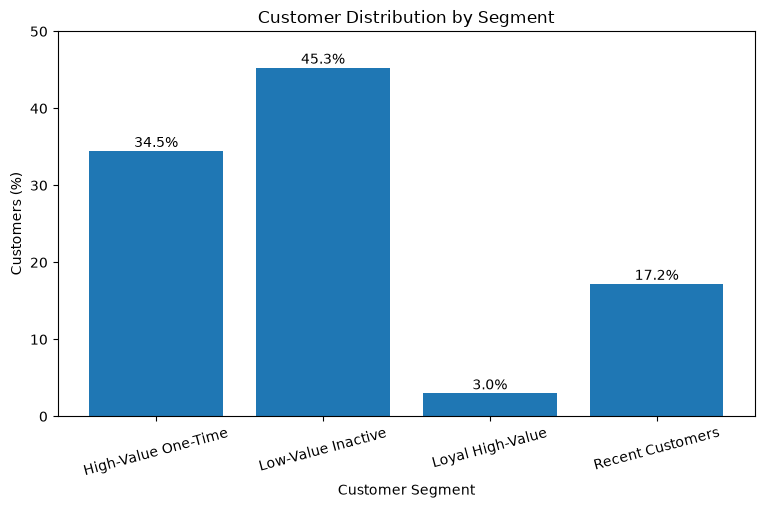

In [102]:
# Calculate customer distribution by segment
segment_distribution = (
    rfm["Segment"]
    .value_counts()
    .reindex(cluster_names.values())
)

segment_percentage = segment_distribution / len(rfm) * 100

plt.figure(figsize=(9, 5))

bars = plt.bar(
    segment_percentage.index,
    segment_percentage.values
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Customers (%)")
plt.xticks(rotation=15)
plt.ylim(0, 50)

for bar, value in zip(bars, segment_percentage.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.show()

#### **RFM Profile by Customer Segment**

In [103]:
# Calculate average RFM values by segment
segment_profile = (
    rfm
    .groupby("Segment")[["Recency", "Frequency", "Monetary"]]
    .mean()
    .round(2)
)

segment_profile

,Recency,Frequency,Monetary
Segment,,,
High-Value One-Time,272.48,1.00,295.78
Low-Value Inactive,287.33,1.00,68.21
Loyal High-Value,220.29,2.11,308.59
Recent Customers,42.02,1.00,133.91


In [104]:
# Normalize segment profiles for visualization
profile_scaled = (
    segment_profile - segment_profile.mean()
) / segment_profile.std()

profile_scaled.round(2)

,Recency,Frequency,Monetary
Segment,,,
High-Value One-Time,0.59,-0.5,0.79
Low-Value Inactive,0.73,-0.5,-1.12
Loyal High-Value,0.13,1.5,0.90
Recent Customers,-1.45,-0.5,-0.57


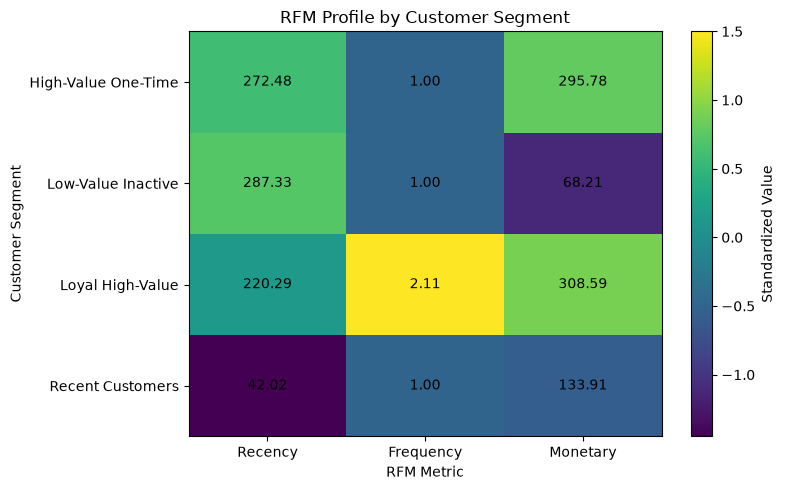

In [105]:
# Visualize RFM characteristics of customer segments
fig, ax = plt.subplots(figsize=(8, 5))

heatmap = ax.imshow(profile_scaled.values, aspect="auto")

ax.set_xticks(range(len(profile_scaled.columns)))
ax.set_xticklabels(profile_scaled.columns)

ax.set_yticks(range(len(profile_scaled.index)))
ax.set_yticklabels(profile_scaled.index)

for i in range(len(profile_scaled.index)):
    for j in range(len(profile_scaled.columns)):
        ax.text(
            j,
            i,
            f"{segment_profile.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("RFM Profile by Customer Segment")
plt.xlabel("RFM Metric")
plt.ylabel("Customer Segment")

plt.colorbar(heatmap, label="Standardized Value")
plt.tight_layout()
plt.show()

- Loyal High-Value là nhóm khách hàng có giá trị nhất với Frequency trung bình 2.11 và Monetary cao nhất ở mức 308.59, tuy nhiên nhóm này chỉ chiếm 3% tổng số khách hàng.
- High-Value One-Time có mức chi tiêu tương đối cao (295.78) nhưng chỉ mua một lần, cho thấy tiềm năng lớn để chuyển đổi thành khách hàng mua lặp lại.
- Recent Customers có Recency thấp nhất, chỉ khoảng 42 ngày, cho thấy đây là nhóm khách hàng tương tác gần đây và có tiềm năng phát triển thành khách hàng trung thành.
- Low-Value Inactive là nhóm lớn nhất nhưng có mức chi tiêu thấp và thời gian kể từ lần mua gần nhất cao, cho thấy mức độ gắn kết tương đối thấp.

==> Kết quả phân nhóm cho thấy cơ hội quan trọng nằm ở việc duy trì Loyal High-Value và thúc đẩy High-Value One-Time cùng Recent Customers quay lại mua hàng.

## **Predictive Analytics - Customer Satisfaction Prediction**

In [106]:
# Create customer dissatisfaction target
reviews["is_dissatisfied"] = (
    reviews["review_score"] <= 3
).astype(int)

reviews["is_dissatisfied"].value_counts()

is_dissatisfied
0    76470
1    22754
Name: count, dtype: int64

In [107]:
# Check target distribution
target_distribution = (
    reviews["is_dissatisfied"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(f"Satisfied: {target_distribution[0]:.2f}%")
print(f"Dissatisfied: {target_distribution[1]:.2f}%")

Satisfied: 77.07%
Dissatisfied: 22.93%


- Khoảng 22.93% đánh giá thuộc nhóm không hài lòng (review score ≤ 3), trong khi 77.07% thuộc nhóm hài lòng.
- Target có sự mất cân bằng nhất định, do đó Accuracy sẽ không được sử dụng riêng lẻ để đánh giá mô hình. Các chỉ số Precision, Recall, F1-score và ROC-AUC cũng sẽ được xem xét.

In [108]:
# Create base dataset for satisfaction prediction
ml_data = orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "delivery_days",
        "delivery_delay_days",
        "is_late"
    ]
].merge(
    reviews[
        ["order_id", "is_dissatisfied"]
    ],
    on="order_id",
    how="inner"
)

ml_data.head()

,order_id,order_purchase_timestamp,delivery_days,delivery_delay_days,is_late,is_dissatisfied
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,8.436574,-7.107488,0.0,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,13.782037,-5.355729,0.0,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,9.394213,-17.245498,0.0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,13.208750,-12.980069,0.0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2.873877,-9.238171,0.0,0


In [109]:
# Check prediction dataset
print(f"Rows: {len(ml_data)}")
print(f"Unique orders: {ml_data['order_id'].nunique()}")
print(ml_data.isnull().sum())

Rows: 99224
Unique orders: 98673
order_id                       0
order_purchase_timestamp       0
delivery_days               2865
delivery_delay_days         2865
is_late                     2865
is_dissatisfied                0
dtype: int64


In [110]:
# Check orders with multiple reviews
review_counts = reviews["order_id"].value_counts()

print(f"Orders with multiple reviews: {(review_counts > 1).sum()}")
print(f"Maximum reviews per order: {review_counts.max()}")

review_counts[review_counts > 1].value_counts().sort_index()

Orders with multiple reviews: 547
Maximum reviews per order: 3


count
2    543
3      4
Name: count, dtype: int64

In [111]:
# Check conflicting review scores
review_score_check = (
    reviews
    .groupby("order_id")["review_score"]
    .nunique()
)

print(
    f"Orders with conflicting review scores: "
    f"{(review_score_check > 1).sum()}"
)

Orders with conflicting review scores: 202


In [112]:
# Create one dissatisfaction target for each order
order_reviews = (
    reviews
    .groupby("order_id", as_index=False)
    .agg(
        is_dissatisfied=("is_dissatisfied", "max")
    )
)

print(f"Rows: {len(order_reviews)}")
print(f"Unique orders: {order_reviews['order_id'].nunique()}")

order_reviews["is_dissatisfied"].value_counts()

Rows: 98673
Unique orders: 98673


is_dissatisfied
0    76002
1    22671
Name: count, dtype: int64

In [113]:
# Rebuild prediction dataset with one target per order
ml_data = orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "delivery_days",
        "delivery_delay_days",
        "is_late"
    ]
].merge(
    order_reviews,
    on="order_id",
    how="inner"
)

print(f"Rows: {len(ml_data)}")
print(f"Unique orders: {ml_data['order_id'].nunique()}")
print(ml_data.isnull().sum())

Rows: 98673
Unique orders: 98673
order_id                       0
order_purchase_timestamp       0
delivery_days               2843
delivery_delay_days         2843
is_late                     2843
is_dissatisfied                0
dtype: int64


### **Order-Level Feature Engineering**

In [114]:
# Aggregate order item features
order_item_features = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(
        item_count=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        seller_count=("seller_id", "nunique")
    )
)

order_item_features.head()

,order_id,item_count,total_price,total_freight,seller_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1


In [115]:
# Add order item features to prediction dataset
ml_data = ml_data.merge(
    order_item_features,
    on="order_id",
    how="left"
)

print(f"Rows: {len(ml_data)}")
print(f"Unique orders: {ml_data['order_id'].nunique()}")
print(ml_data.isnull().sum())

Rows: 98673
Unique orders: 98673
order_id                       0
order_purchase_timestamp       0
delivery_days               2843
delivery_delay_days         2843
is_late                     2843
is_dissatisfied                0
item_count                   756
total_price                  756
total_freight                756
seller_count                 756
dtype: int64


### **Payment Feature Engineering**

In [116]:
# Aggregate payment features by order
payment_features = (
    payments
    .groupby("order_id", as_index=False)
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
        payment_count=("payment_sequential", "count")
    )
)

payment_features.head()

,order_id,payment_value,payment_installments,payment_count
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2,1
1,00018f77f2f0320c557190d7a144bdd3,259.83,3,1
2,000229ec398224ef6ca0657da4fc703e,216.87,5,1
3,00024acbcdf0a6daa1e931b038114c75,25.78,2,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,1


In [117]:
# Add payment features to prediction dataset
ml_data = ml_data.merge(
    payment_features,
    on="order_id",
    how="left"
)

print(f"Rows: {len(ml_data)}")
print(f"Unique orders: {ml_data['order_id'].nunique()}")
print(ml_data.isnull().sum())

Rows: 98673
Unique orders: 98673
order_id                       0
order_purchase_timestamp       0
delivery_days               2843
delivery_delay_days         2843
is_late                     2843
is_dissatisfied                0
item_count                   756
total_price                  756
total_freight                756
seller_count                 756
payment_value                  1
payment_installments           1
payment_count                  1
dtype: int64


### **Time Feature Engineering**

In [118]:
# Create time-based features from purchase timestamp
ml_data["purchase_month"] = ml_data["order_purchase_timestamp"].dt.month
ml_data["purchase_dayofweek"] = ml_data["order_purchase_timestamp"].dt.dayofweek
ml_data["purchase_hour"] = ml_data["order_purchase_timestamp"].dt.hour
ml_data["is_weekend"] = (
    ml_data["purchase_dayofweek"] >= 5
).astype(int)

ml_data[
    [
        "order_purchase_timestamp",
        "purchase_month",
        "purchase_dayofweek",
        "purchase_hour",
        "is_weekend"
    ]
].head()

C:\Users\t14\AppData\Local\Temp\ipykernel_7648\1967821835.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ml_data["purchase_dayofweek"] = ml_data["order_purchase_timestamp"].dt.dayofweek


,order_purchase_timestamp,purchase_month,purchase_dayofweek,purchase_hour,is_weekend
0,2017-10-02 10:56:33,10,0,10,0
1,2018-07-24 20:41:37,7,1,20,0
2,2018-08-08 08:38:49,8,2,8,0
3,2017-11-18 19:28:06,11,5,19,1
4,2018-02-13 21:18:39,2,1,21,0


### **Prepare Data for Prediction Model**

In [119]:
# Select features for dissatisfaction prediction
model_features = [
    "delivery_days",
    "delivery_delay_days",
    "is_late",
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "payment_value",
    "payment_installments",
    "payment_count",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
    "is_weekend"
]

model_data = ml_data[
    model_features + ["is_dissatisfied"]
].copy()

print(f"Rows: {len(model_data)}")
print(f"Features: {len(model_features)}")
print(model_data.isnull().sum())

Rows: 98673
Features: 14
delivery_days           2843
delivery_delay_days     2843
is_late                 2843
item_count               756
total_price              756
total_freight            756
seller_count             756
payment_value              1
payment_installments       1
payment_count              1
purchase_month             0
purchase_dayofweek         0
purchase_hour              0
is_weekend                 0
is_dissatisfied            0
dtype: int64


In [120]:
# Remove rows with missing prediction features
model_data_clean = model_data.dropna().copy()

print(f"Rows before cleaning: {len(model_data)}")
print(f"Rows after cleaning: {len(model_data_clean)}")
print(f"Rows removed: {len(model_data) - len(model_data_clean)}")

print("\nMissing values:")
print(model_data_clean.isnull().sum())

Rows before cleaning: 98673
Rows after cleaning: 95829
Rows removed: 2844

Missing values:
delivery_days           0
delivery_delay_days     0
is_late                 0
item_count              0
total_price             0
total_freight           0
seller_count            0
payment_value           0
payment_installments    0
payment_count           0
purchase_month          0
purchase_dayofweek      0
purchase_hour           0
is_weekend              0
is_dissatisfied         0
dtype: int64


In [121]:
# Check target distribution after cleaning
target_counts = model_data_clean["is_dissatisfied"].value_counts()
target_percent = (
    model_data_clean["is_dissatisfied"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Target counts:")
print(target_counts)

print("\nTarget percentage:")
print(target_percent)

Target counts:
is_dissatisfied
0    75595
1    20234
Name: count, dtype: int64

Target percentage:
is_dissatisfied
0    78.89
1    21.11
Name: proportion, dtype: float64


### **Train-Test Split**

In [122]:
# Import model preparation tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [123]:
# Separate features and target
X = model_data_clean[model_features]
y = model_data_clean["is_dissatisfied"]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (95829, 14)
y shape: (95829,)


In [124]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")

print("\nTraining target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training rows: 76663
Testing rows: 19166

Training target distribution:
is_dissatisfied
0    78.89
1    21.11
Name: proportion, dtype: float64

Testing target distribution:
is_dissatisfied
0    78.88
1    21.12
Name: proportion, dtype: float64


### **Feature Scaling**

In [125]:
# Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Scaled training shape: {X_train_scaled.shape}")
print(f"Scaled testing shape: {X_test_scaled.shape}")

Scaled training shape: (76663, 14)
Scaled testing shape: (19166, 14)


In [126]:
# Convert scaled arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=model_features,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=model_features,
    index=X_test.index
)

X_train_scaled.describe().round(2)

,delivery_days,delivery_delay_days,is_late,item_count,total_price,total_freight,seller_count,payment_value,payment_installments,payment_count,purchase_month,purchase_dayofweek,purchase_hour,is_weekend
count,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00,76663.00
mean,-0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.24,-13.34,-0.29,-0.27,-0.66,-1.05,-0.11,-0.70,-1.08,-0.12,-1.56,-1.40,-2.77,-0.54
25%,-0.61,-0.50,-0.29,-0.27,-0.44,-0.41,-0.11,-0.45,-0.71,-0.12,-0.94,-0.89,-0.71,-0.54
50%,-0.24,-0.07,-0.29,-0.27,-0.24,-0.26,-0.11,-0.25,-0.34,-0.12,-0.01,0.13,0.04,-0.54
75%,0.33,0.48,-0.29,-0.27,0.07,0.06,-0.11,0.08,0.40,-0.12,0.61,0.64,0.79,-0.54
max,20.69,19.81,3.39,37.59,65.04,81.70,32.47,63.04,7.78,68.35,1.85,1.65,1.54,1.84


## **Logistic Regression**

In [127]:
from sklearn.linear_model import LogisticRegression

In [128]:
# Train Logistic Regression model
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### **Model Evaluation**

In [129]:
# Make predictions on test data
y_pred_log = log_model.predict(X_test_scaled)
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

print(f"Predictions: {len(y_pred_log)}")
print(f"Predicted dissatisfied: {y_pred_log.sum()}")

Predictions: 19166
Predicted dissatisfied: 1634


### **Classification Metrics**

In [130]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate Logistic Regression metrics
accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)
roc_auc = roc_auc_score(y_test, y_prob_log)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.8163
Precision: 0.6610
Recall:    0.2669
F1-score:  0.3802
ROC-AUC:   0.6905


- Logistic Regression đạt Accuracy 81,63%, nhưng chỉ phát hiện được 26,69% khách hàng thực sự không hài lòng.
- Precision đạt 66,10%, cho thấy các trường hợp được mô hình dự đoán là không hài lòng có độ chính xác tương đối tốt.
- ROC-AUC đạt 0,6905, cho thấy mô hình có khả năng phân biệt hai nhóm khách hàng ở mức trung bình.

In [131]:
# Import evaluation tools
from sklearn.metrics import classification_report, confusion_matrix

# Classification report
print("Logistic Regression Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=["Satisfied", "Dissatisfied"]
))

Logistic Regression Classification Report:

              precision    recall  f1-score   support

   Satisfied       0.83      0.96      0.89     15119
Dissatisfied       0.66      0.27      0.38      4047

    accuracy                           0.82     19166
   macro avg       0.75      0.62      0.64     19166
weighted avg       0.79      0.82      0.78     19166



In [132]:
# Create confusion matrix
cm_log = confusion_matrix(y_test, y_pred_log)

print("Confusion Matrix:")
print(cm_log)

Confusion Matrix:
[[14565   554]
 [ 2967  1080]]


## **Random Forest**

In [133]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [134]:
# Make predictions with Random Forest
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print(f"Predictions: {len(y_pred_rf)}")
print(f"Predicted dissatisfied: {y_pred_rf.sum()}")

Predictions: 19166
Predicted dissatisfied: 1403


In [135]:
# Evaluate Random Forest
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Accuracy:  0.8223
Precision: 0.7284
Recall:    0.2525
F1-score:  0.3750
ROC-AUC:   0.6819


- Random Forest đạt Accuracy 82,23% và Precision 72,84%, cao hơn Logistic Regression.
- Tuy nhiên, Recall chỉ đạt 25,25%, nghĩa là mô hình bỏ sót phần lớn khách hàng thực sự không hài lòng.
- Việc sử dụng mô hình phức tạp hơn chưa mang lại sự cải thiện rõ rệt trong khả năng phát hiện khách hàng không hài lòng.

In [136]:
# Random Forest classification report
print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Satisfied", "Dissatisfied"]
))

# Create confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

Random Forest Classification Report:

              precision    recall  f1-score   support

   Satisfied       0.83      0.97      0.90     15119
Dissatisfied       0.73      0.25      0.38      4047

    accuracy                           0.82     19166
   macro avg       0.78      0.61      0.64     19166
weighted avg       0.81      0.82      0.79     19166

Confusion Matrix:
[[14738   381]
 [ 3025  1022]]


## **Model Comparison**

In [137]:
# Store Logistic Regression evaluation metrics
log_accuracy = accuracy_score(y_test, y_pred_log)
log_precision = precision_score(y_test, y_pred_log)
log_recall = recall_score(y_test, y_pred_log)
log_f1 = f1_score(y_test, y_pred_log)
log_roc_auc = roc_auc_score(y_test, y_prob_log)

print(f"Accuracy:  {log_accuracy:.4f}")
print(f"Precision: {log_precision:.4f}")
print(f"Recall:    {log_recall:.4f}")
print(f"F1-score:  {log_f1:.4f}")
print(f"ROC-AUC:   {log_roc_auc:.4f}")

Accuracy:  0.8163
Precision: 0.6610
Recall:    0.2669
F1-score:  0.3802
ROC-AUC:   0.6905


In [138]:
# Compare model performance
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy],
    "Precision": [log_precision, rf_precision],
    "Recall": [log_recall, rf_recall],
    "F1-score": [log_f1, rf_f1],
    "ROC-AUC": [log_roc_auc, rf_roc_auc]
})

model_comparison.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8163,0.6610,0.2669,0.3802,0.6905
Random Forest,0.8223,0.7284,0.2525,0.3750,0.6819


- Random Forest tốt hơn về Accuracy và Precision, trong khi Logistic Regression tốt hơn về Recall, F1-score và ROC-AUC.
- Vì mục tiêu chính là nhận diện khách hàng không hài lòng, Logistic Regression cho thấy sự cân bằng phù hợp hơn giữa các chỉ số đánh giá.
- Tuy nhiên, Recall của cả hai mô hình vẫn còn thấp, cho thấy cần bổ sung thêm các đặc trưng liên quan đến hành vi khách hàng hoặc chất lượng dịch vụ để cải thiện khả năng dự đoán.

### **Model Performance Comparison**

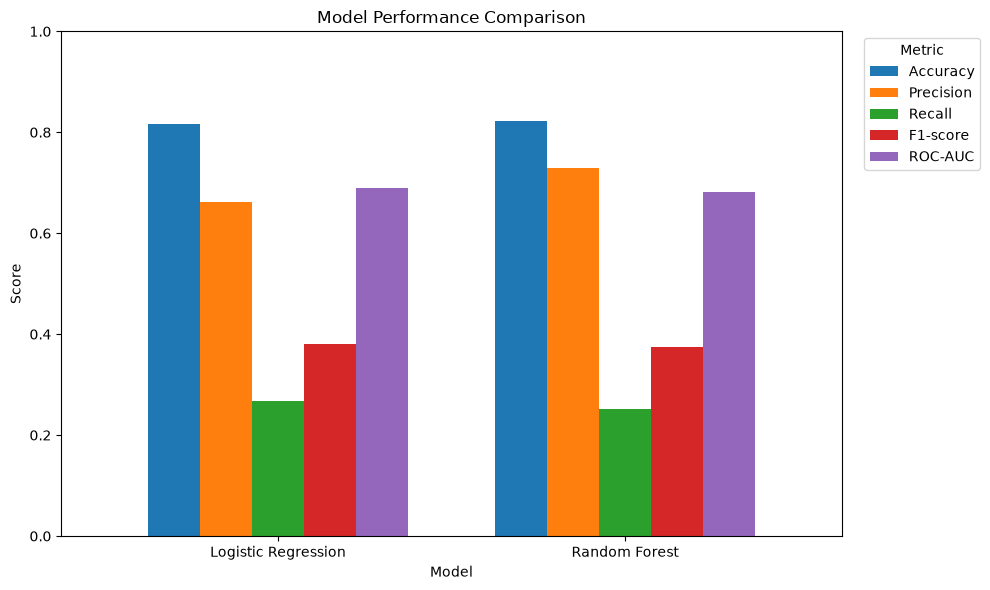

In [139]:
# Visualize model performance comparison
comparison_plot = model_comparison.set_index("Model")

ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### **ROC Curve Comparison**

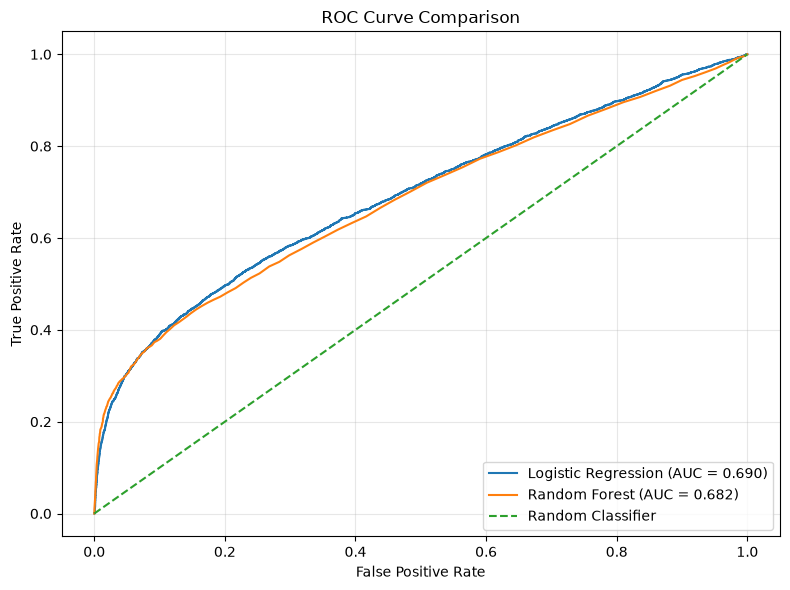

In [140]:
# Calculate ROC curves
from sklearn.metrics import roc_curve

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {log_roc_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **Feature Importance Analysis**

In [141]:
# Extract Random Forest feature importance
feature_importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance.round(4)

,Feature,Importance
0,delivery_delay_days,0.1965
1,delivery_days,0.1651
2,payment_value,0.1167
3,total_freight,0.1136
4,total_price,0.1081
5,purchase_hour,0.0780
6,purchase_month,0.0578
7,purchase_dayofweek,0.0438
8,payment_installments,0.0418
9,is_late,0.0371


- Các đặc trưng liên quan đến quá trình giao hàng có mức độ quan trọng cao nhất trong việc dự đoán sự không hài lòng của khách hàng.
- `delivery_delay_days` và `delivery_days` là hai đặc trưng quan trọng nhất, cho thấy hiệu suất giao hàng có mối liên hệ mạnh với trải nghiệm khách hàng.
- Các yếu tố về giá trị thanh toán, phí vận chuyển và giá trị đơn hàng cũng đóng góp đáng kể vào khả năng dự đoán của mô hình.

### **Top Features Influencing Customer Dissatisfaction**

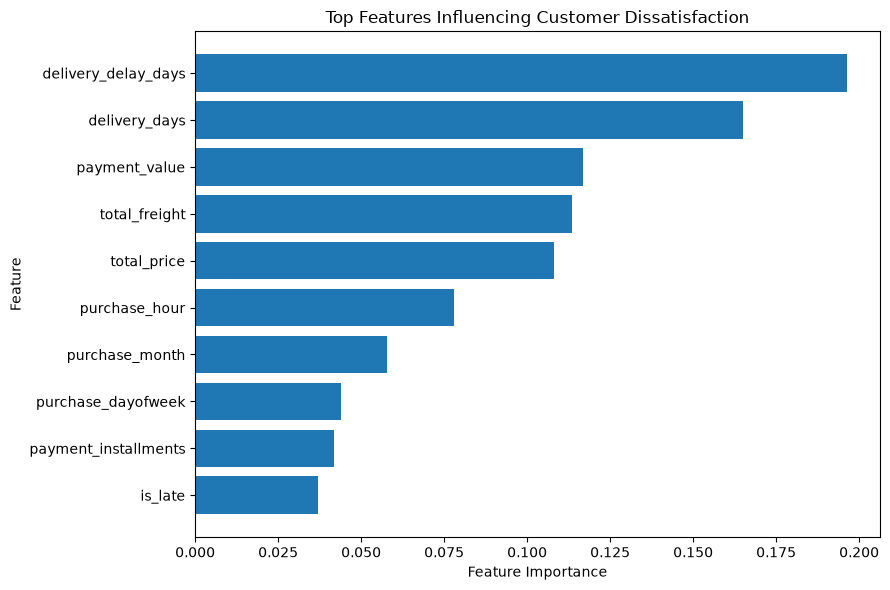

In [142]:
# Visualize feature importance
top_features = feature_importance.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top Features Influencing Customer Dissatisfaction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## **Delivery Delay Impact Analysis**

In [143]:
# Compare dissatisfaction rate by delivery status
delivery_impact = (
    model_data_clean
    .groupby("is_late")["is_dissatisfied"]
    .agg(
        Orders="count",
        Dissatisfied_Customers="sum",
        Dissatisfaction_Rate="mean"
    )
)

delivery_impact["Dissatisfaction_Rate"] *= 100

delivery_impact.index = delivery_impact.index.map({
    0: "On-Time / Early",
    1: "Late"
})

delivery_impact.round(2)

,Orders,Dissatisfied_Customers,Dissatisfaction_Rate
is_late,,,
On-Time / Early,88168,15219,17.26
Late,7661,5015,65.46


- Tỷ lệ khách hàng không hài lòng ở các đơn giao trễ đạt 65,46%, cao hơn đáng kể so với 17,26% ở các đơn giao đúng hạn hoặc sớm.
- Như vậy, tỷ lệ không hài lòng của nhóm giao trễ cao khoảng 3,8 lần so với nhóm giao đúng hạn hoặc sớm.
- Kết quả này củng cố phát hiện từ Feature Importance rằng hiệu suất giao hàng là một trong những yếu tố quan trọng nhất liên quan đến sự không hài lòng của khách hàng.

==> Do đó, giảm tình trạng giao hàng trễ là một trong những hướng ưu tiên để cải thiện trải nghiệm khách hàng.

### **Dissatisfaction Rate by Delivery Status**

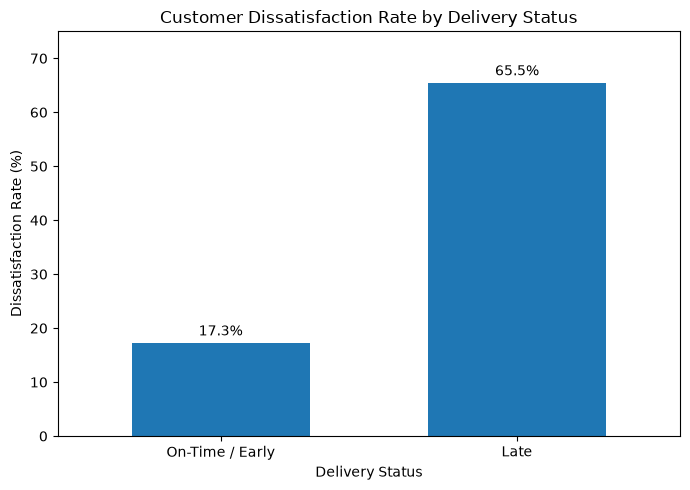

In [144]:
# Visualize dissatisfaction rate by delivery status
ax = delivery_impact["Dissatisfaction_Rate"].plot(
    kind="bar",
    figsize=(7, 5),
    width=0.6
)

plt.title("Customer Dissatisfaction Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Dissatisfaction Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 75)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

In [145]:
# Delivery Delay Severity Analysis

def categorize_delay(days):
    if days <= 0:
        return "On-Time / Early"
    elif days <= 3:
        return "1-3 Days Late"
    elif days <= 7:
        return "4-7 Days Late"
    elif days <= 14:
        return "8-14 Days Late"
    else:
        return ">14 Days Late"

model_data_clean["delay_group"] = (
    model_data_clean["delivery_delay_days"]
    .apply(categorize_delay)
)

model_data_clean["delay_group"].value_counts()

delay_group
On-Time / Early    88168
1-3 Days Late       2636
4-7 Days Late       1773
8-14 Days Late      1749
>14 Days Late       1503
Name: count, dtype: int64

In [146]:
# Calculate Dissatisfaction Rate by Delay Severity

delay_severity = (
    model_data_clean
    .groupby("delay_group", observed=True)["is_dissatisfied"]
    .agg(
        Orders="count",
        Dissatisfied_Customers="sum",
        Dissatisfaction_Rate="mean"
    )
)

delay_severity["Dissatisfaction_Rate"] *= 100

delay_order = [
    "On-Time / Early",
    "1-3 Days Late",
    "4-7 Days Late",
    "8-14 Days Late",
    ">14 Days Late"
]

delay_severity = delay_severity.reindex(delay_order)

delay_severity.round(2)

,Orders,Dissatisfied_Customers,Dissatisfaction_Rate
delay_group,,,
On-Time / Early,88168,15219,17.26
1-3 Days Late,2636,890,33.76
4-7 Days Late,1773,1279,72.14
8-14 Days Late,1749,1527,87.31
>14 Days Late,1503,1319,87.76


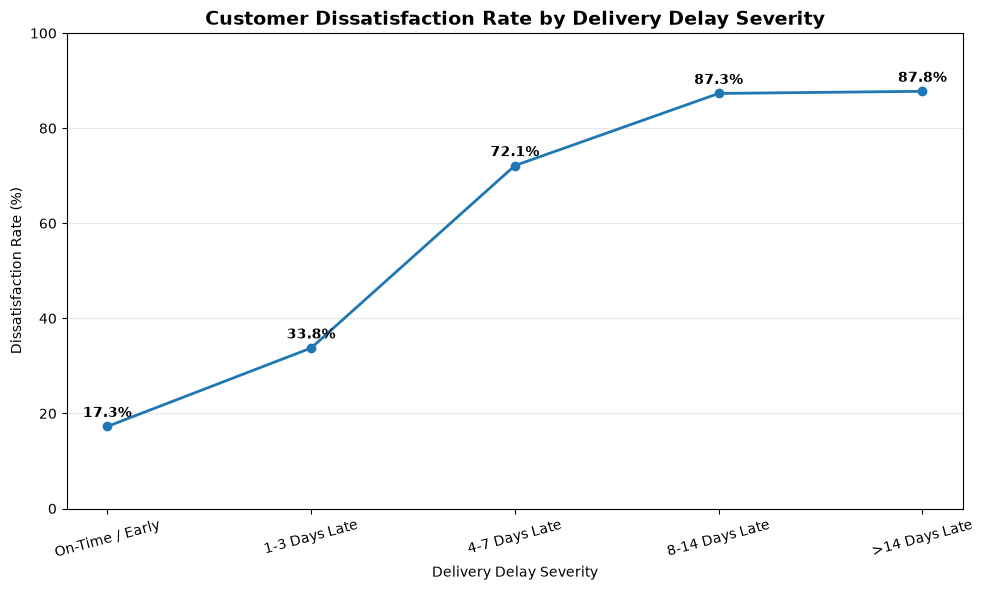

In [147]:
# Visualize Dissatisfaction Rate by Delivery Delay Severity

plt.figure(figsize=(10, 6))

plt.plot(
    delay_severity.index,
    delay_severity["Dissatisfaction_Rate"],
    marker="o",
    linewidth=2
)

plt.title(
    "Customer Dissatisfaction Rate by Delivery Delay Severity",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Delivery Delay Severity")
plt.ylabel("Dissatisfaction Rate (%)")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(delay_severity["Dissatisfaction_Rate"]):
    plt.text(
        i,
        value + 2,
        f"{value:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

- Tỷ lệ khách hàng không hài lòng tăng rõ rệt theo mức độ giao trễ, từ 17,26% ở nhóm giao đúng hạn hoặc sớm lên 33,76% khi trễ 1–3 ngày và 72,14% khi trễ 4–7 ngày.
- Khi đơn hàng trễ từ 8 ngày trở lên, tỷ lệ không hài lòng vượt 87%, cho thấy trải nghiệm khách hàng suy giảm mạnh khi thời gian giao trễ kéo dài.
- Mức tăng từ nhóm 8–14 ngày (87,31%) sang trên 14 ngày (87,76%) không còn đáng kể, cho thấy tỷ lệ không hài lòng đã đạt mức rất cao từ khoảng 8 ngày trễ.
- Kết quả này củng cố phát hiện từ mô hình Random Forest rằng `delivery_delay_days` là một trong những đặc trưng dự đoán quan trọng nhất đối với sự không hài lòng của khách hàng.

## Overall Insights

- Phân tích RFM và K-Means cho thấy khách hàng có sự khác biệt rõ rệt về mức độ mua hàng, tần suất giao dịch và giá trị chi tiêu, giúp doanh nghiệp xác định các nhóm khách hàng có giá trị và hành vi khác nhau để xây dựng chiến lược chăm sóc phù hợp.

- Phân tích Machine Learning cho thấy Logistic Regression và Random Forest đều đạt Accuracy trên 81%, tuy nhiên khả năng phát hiện khách hàng không hài lòng vẫn còn hạn chế. Logistic Regression có Recall, F1-score và ROC-AUC nhỉnh hơn, trong khi Random Forest có Accuracy và Precision cao hơn.

- Feature Importance từ Random Forest cho thấy các yếu tố liên quan đến giao hàng, đặc biệt là `delivery_delay_days` và `delivery_days`, nằm trong nhóm đặc trưng quan trọng nhất đối với việc dự đoán sự không hài lòng của khách hàng.

- Phân tích thực tế tiếp tục củng cố kết quả của mô hình: tỷ lệ không hài lòng ở đơn giao trễ đạt 65,46%, cao khoảng 3,8 lần so với 17,26% ở đơn giao đúng hạn hoặc sớm.

- Mức độ giao trễ càng nghiêm trọng, tỷ lệ không hài lòng càng tăng mạnh: từ 33,76% khi trễ 1–3 ngày lên 72,14% khi trễ 4–7 ngày và trên 87% khi trễ từ 8 ngày trở lên.

- Nhìn chung, kết quả cho thấy bên cạnh việc phân nhóm khách hàng để xây dựng chiến lược kinh doanh phù hợp, hiệu suất giao hàng là một trong những yếu tố vận hành nổi bật có liên hệ mạnh với trải nghiệm khách hàng. Doanh nghiệp nên ưu tiên kiểm soát tình trạng giao trễ, chủ động xử lý các đơn có nguy cơ chậm và có chính sách chăm sóc phù hợp đối với những khách hàng chịu ảnh hưởng.